## Imports

In [1]:
import glob, json, numpy as np, pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from sklearn.random_projection import GaussianRandomProjection
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import os

## Load last layer vector

In [2]:
def load_npz(path):
    z = np.load(path, allow_pickle=True)
    X = z["X"]
    concepts = z["concepts"]
    surfaces = z["surfaces"]
    meta = json.loads(str(z["meta"].item())) if z["meta"].dtype == object else json.loads(str(z["meta"]))
    return X, concepts, surfaces, meta

all_paths = sorted(glob.glob("invariance_outputs_nb/*/*.npz"))
last_paths = sorted(glob.glob("invariance_outputs_nb/*/*_layerLAST*.npz"))
nonlast_paths = [p for p in all_paths if "layerLAST" not in os.path.basename(p)]
paths = nonlast_paths

rows = []
blocks = []
for p in paths:
    X, c, s, m = load_npz(p)
    model = m["model_id"]
    d = X.shape[1]
    rows.append({"path": p, "model": model, "layer": m["layer_index_0based"]+1, "N": X.shape[0], "d": d})
    blocks.append((X, c, s, model, m))
manifest = pd.DataFrame(rows)
display(manifest)

,path,model,layer,N,d
0,invariance_outputs_nb/Qwen_Qwen2.5-7B-Instruct...,Qwen/Qwen2.5-7B-Instruct,6,250,3584
1,invariance_outputs_nb/THUDM_glm-4-9b-chat/thud...,THUDM/glm-4-9b-chat,39,250,4096
2,invariance_outputs_nb/TinyLlama_TinyLlama-1.1B...,TinyLlama/TinyLlama-1.1B-Chat-v1.0,3,250,2048
3,invariance_outputs_nb/deepseek-ai_deepseek-llm...,deepseek-ai/deepseek-llm-7b-chat,2,250,4096
4,invariance_outputs_nb/google_gemma-1.1-2b-it/g...,google/gemma-1.1-2b-it,9,250,2048
5,invariance_outputs_nb/internlm_internlm2-chat-...,internlm/internlm2-chat-7b,2,250,4096
6,invariance_outputs_nb/meta-llama_Meta-Llama-3-...,meta-llama/Meta-Llama-3-8B-Instruct,2,250,4096
7,invariance_outputs_nb/mistralai_Mistral-7B-Ins...,mistralai/Mistral-7B-Instruct-v0.3,2,250,4096
8,invariance_outputs_nb/openai-community_gpt2/op...,openai-community/gpt2,3,250,768


## PCA

In [3]:
# BREAKPOINT_0

In [4]:
# project each block into k-dim with JL
k = 256
rng_seed = 42

def project_to_common(X, k, random_state):
    rp = GaussianRandomProjection(n_components=k, random_state=random_state)
    return rp.fit_transform(X.astype(np.float64))

Xk_list, C_list, S_list, M_list = [], [], [], []
for X, c, s, model, meta in blocks:
    Xk = project_to_common(X, k, random_state=rng_seed)
    Xk_list.append(Xk)
    C_list.append(c)
    S_list.append(s)
    M_list.append(np.array([model]*len(c), dtype=object))

Xk_all = np.vstack(Xk_list)
concept_all = np.concatenate(C_list)
surface_all = np.concatenate(S_list)
model_all = np.concatenate(M_list)

# global standardize
Xk_all = StandardScaler(with_mean=True, with_std=True).fit_transform(Xk_all)

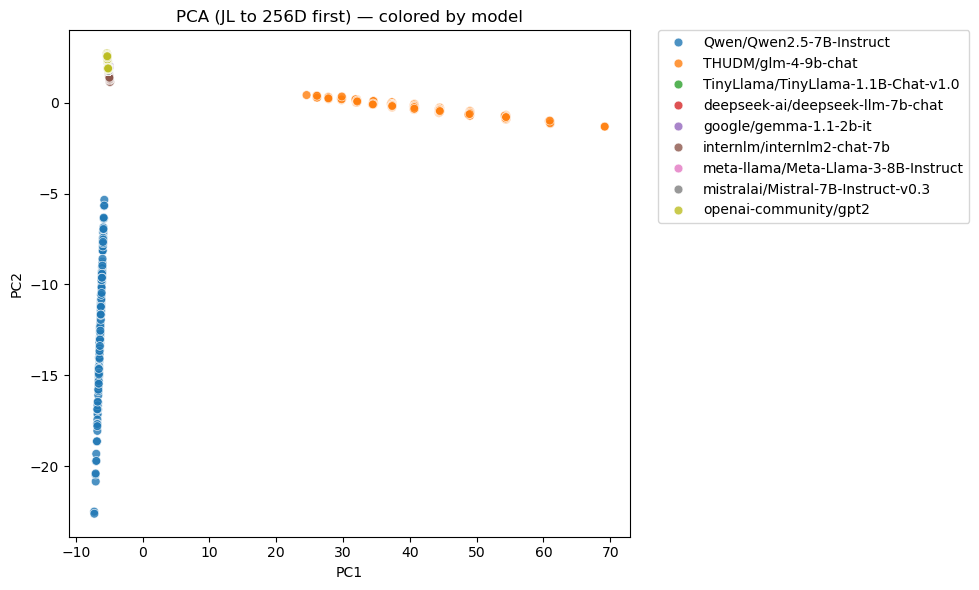

In [5]:
# PCA
pca = PCA(n_components=2, random_state=0)
X2 = pca.fit_transform(Xk_all)

df_pca = pd.DataFrame({
    "PC1": X2[:,0],
    "PC2": X2[:,1],
    "Model": model_all
})

plt.figure(figsize=(10,6))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Model", palette="tab10", s=40, alpha=0.8)
plt.title("PCA (JL to 256D first) — colored by model")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

plot_path = os.path.join("invariance_outputs_nb", f"PCA.png")
plt.savefig(plot_path, dpi=200)
plt.show()

## t-SNE

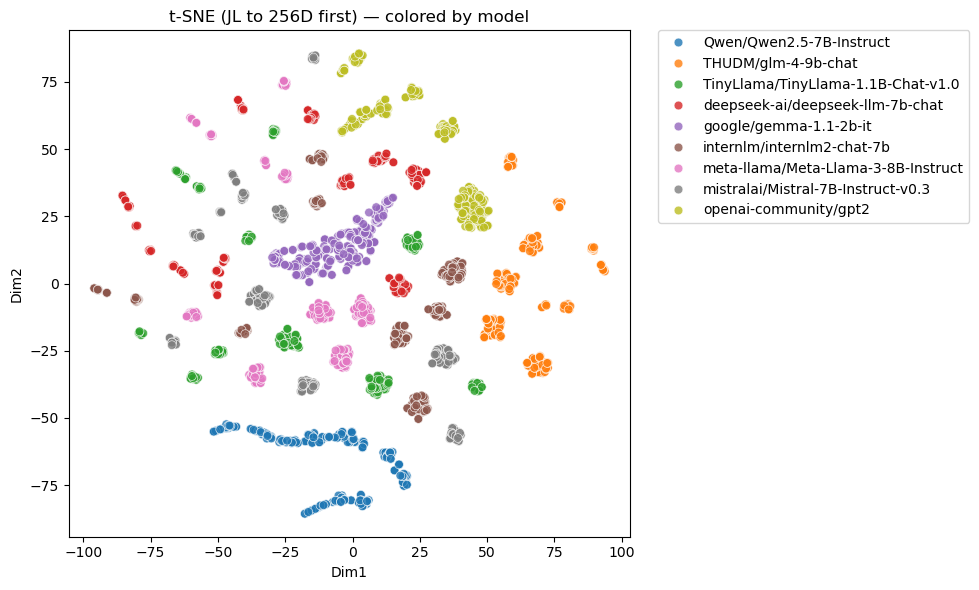

In [6]:
# t-SNE
tsne = TSNE(n_components=2, perplexity=10, random_state=0)
Xts = tsne.fit_transform(Xk_all)

df_tsne = pd.DataFrame({
    "Dim1": Xts[:,0],
    "Dim2": Xts[:,1],
    "Model": model_all
})

plt.figure(figsize=(10,6))
sns.scatterplot(data=df_tsne, x="Dim1", y="Dim2", hue="Model", palette="tab10", s=40, alpha=0.8)
plt.title("t-SNE (JL to 256D first) — colored by model")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

plot_path = os.path.join("invariance_outputs_nb", f"t-SNE.png")
plt.savefig(plot_path, dpi=200)
plt.show()

## Classification

In [7]:
# BREAKPOINT_1

In [8]:
# === Assumptions ===
# blocks: list of tuples (X, concepts, surfaces, model_label, meta)
#   - X: np.ndarray [N, d] last-layer (or chosen layer) reps
#   - concepts: np.ndarray [N] (your ConceptID / BasePrompt code)
#   - surfaces: np.ndarray [N] (paraphrase index)
#   - model_label: str (e.g., "mistralai/Mistral-7B-Instruct-v0.3")
#   - meta: dict (optional; not used here except for sanity/debug)
#
# If your tuple shape differs, adjust the unpacking in the for-loop below.

import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.random_projection import GaussianRandomProjection
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ---------- Hyperparams ----------
K_COMMON = 256       # JL common dimension
RP_SEED   = 123
N_SPLITS  = 5
RANDOM_STATE = 42
USE_CLASS_WEIGHT = True  # helpful if models are imbalanced

# ---------- Helper: JL projection per block ----------
def jl_project_block(X, k=K_COMMON, seed=RP_SEED):
    rp = GaussianRandomProjection(n_components=k, random_state=seed)
    return rp.fit_transform(X.astype(np.float64))

# ---------- Build dataset from blocks ----------
Xs, y_models, y_concepts = [], [], []
for item in blocks:
    # If your block packs differently, tweak here:
    if len(item) == 5:
        X, concepts, surfaces, model_label, meta = item
    elif len(item) == 4:
        X, concepts, surfaces, model_label = item
        meta = {}
    else:
        raise ValueError("Unexpected blocks tuple shape; expected 4 or 5 elements per block.")

    Xp = jl_project_block(X)                  # [N, K_COMMON]
    Xs.append(Xp)
    y_models.append(np.array([model_label] * len(concepts), dtype=object))
    y_concepts.append(concepts.astype(int))   # group key for leakage-safe splits

X_all      = np.vstack(Xs)                    # [M, K_COMMON]
y_model    = np.concatenate(y_models)         # [M] object labels
group_ids  = np.concatenate(y_concepts)       # [M] ConceptID (for GroupKFold)

# Standardize globally (after JL)
scaler = StandardScaler(with_mean=True, with_std=True)
X_all = scaler.fit_transform(X_all)

# Encode model labels to integers for the classifier
classes, y_int = np.unique(y_model, return_inverse=True)
print("Model classes detected:", classes.tolist())

# ---------- Group-aware CV (held-out prompts) ----------
gkf = GroupKFold(n_splits=N_SPLITS)
fold_rows = []
y_true_all, y_pred_all = [], []

def make_logreg():
    return LogisticRegression(
        solver="saga",
        penalty="l2",
        C=1.0,
        max_iter=5000,
        n_jobs=-1,
        class_weight=("balanced" if USE_CLASS_WEIGHT else None),
        random_state=RANDOM_STATE
    )

for fold, (tr, te) in enumerate(gkf.split(X_all, y_int, groups=group_ids), start=1):
    clf = make_logreg()
    Xtr, Xte = X_all[tr], X_all[te]
    ytr, yte = y_int[tr], y_int[te]

    clf.fit(Xtr, ytr)
    yhat = clf.predict(Xte)

    acc  = accuracy_score(yte, yhat)
    f1m  = f1_score(yte, yhat, average="macro")
    f1w  = f1_score(yte, yhat, average="weighted")
    fold_rows.append({"fold": fold, "acc": acc, "macro_f1": f1m, "weighted_f1": f1w})

    y_true_all.append(yte)
    y_pred_all.append(yhat)

fold_df = pd.DataFrame(fold_rows)
print("\nFold metrics:")
display(fold_df)
print("CV mean ± std:")
print(fold_df.agg(["mean","std"])[["acc","macro_f1","weighted_f1"]])

y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

print("\nClassification report (aggregated across folds):")
print(classification_report(y_true_all, y_pred_all, target_names=classes))

Model classes detected: ['Qwen/Qwen2.5-7B-Instruct', 'THUDM/glm-4-9b-chat', 'TinyLlama/TinyLlama-1.1B-Chat-v1.0', 'deepseek-ai/deepseek-llm-7b-chat', 'google/gemma-1.1-2b-it', 'internlm/internlm2-chat-7b', 'meta-llama/Meta-Llama-3-8B-Instruct', 'mistralai/Mistral-7B-Instruct-v0.3', 'openai-community/gpt2']

Fold metrics:


,fold,acc,macro_f1,weighted_f1
0,1,1.0,1.0,1.0
1,2,1.0,1.0,1.0
2,3,1.0,1.0,1.0
3,4,1.0,1.0,1.0
4,5,1.0,1.0,1.0


CV mean ± std:
      acc  macro_f1  weighted_f1
mean  1.0       1.0          1.0
std   0.0       0.0          0.0

Classification report (aggregated across folds):
                                     precision    recall  f1-score   support

           Qwen/Qwen2.5-7B-Instruct       1.00      1.00      1.00       250
                THUDM/glm-4-9b-chat       1.00      1.00      1.00       250
 TinyLlama/TinyLlama-1.1B-Chat-v1.0       1.00      1.00      1.00       250
   deepseek-ai/deepseek-llm-7b-chat       1.00      1.00      1.00       250
             google/gemma-1.1-2b-it       1.00      1.00      1.00       250
         internlm/internlm2-chat-7b       1.00      1.00      1.00       250
meta-llama/Meta-Llama-3-8B-Instruct       1.00      1.00      1.00       250
 mistralai/Mistral-7B-Instruct-v0.3       1.00      1.00      1.00       250
              openai-community/gpt2       1.00      1.00      1.00       250

                           accuracy                           1.

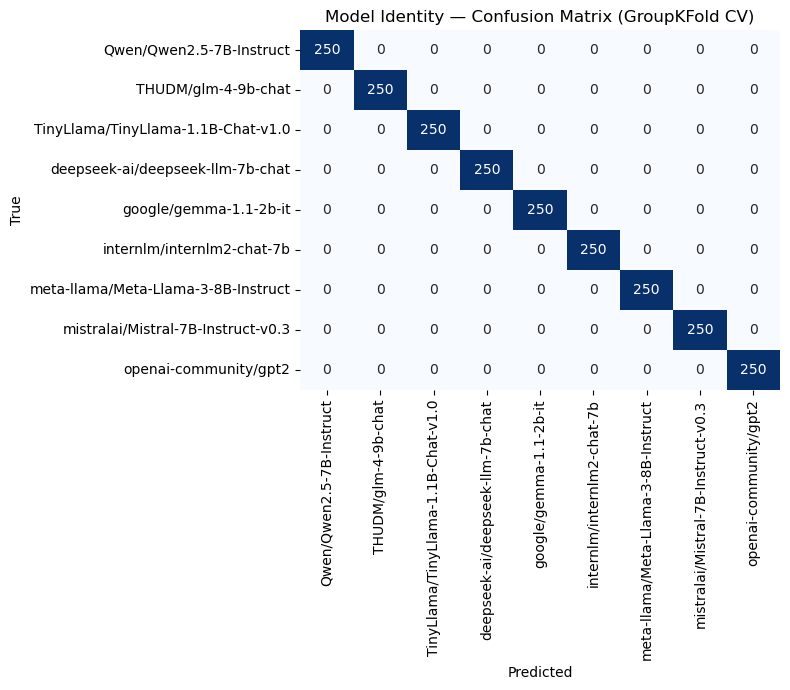

In [9]:
# ---------- Confusion matrix ----------
cm = confusion_matrix(y_true_all, y_pred_all, labels=np.arange(len(classes)))
cm_df = pd.DataFrame(cm, index=classes, columns=classes)

plt.figure(figsize=(8,7))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Model Identity — Confusion Matrix (GroupKFold CV)")
plt.tight_layout()

plot_path = os.path.join("invariance_outputs_nb", f"classification.png")
plt.savefig(plot_path, dpi=200)
plt.show()